# ใบงานที่ 6.2: วิเคราะห์ความสัมพันธ์ RSSI vs Throughput

วิเคราะห์ข้อมูลจากการทดลอง Software Tx-Power Control บน ESP32 (Node A: SoftAP Server, Node B: Station Client)
ตามข้อ 6 ของใบงาน: Scatter Plot, Logarithmic Regression, R² และจุด Threshold RSSI ที่ Throughput ลดลงเกิน 50% จากค่าสูงสุด

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import optimize, stats

plt.rcParams['figure.dpi'] = 110
plt.rcParams['font.size'] = 11


## 1. ข้อมูลจากตารางบันทึกผลการทดลอง

In [2]:
data = {
    "trial": [1, 2, 3, 4, 5],
    "tx_power_dbm": [20, 15, 10, 5, 2],
    "rssi_dbm": [-53.2, -46.44, -50.1, -48.9, -47.9],
    "time_s": [0.1675, 0.1139, 0.1323, 0.1051, 0.1307],
    "throughput_kbps": [1130.92, 3607.86, 3644.65, 3974.27, 3232.71],
}

df = pd.DataFrame(data).sort_values("rssi_dbm").reset_index(drop=True)
df


,trial,tx_power_dbm,rssi_dbm,time_s,throughput_kbps
0,1,20,-53.20,0.1675,1130.92
1,3,10,-50.10,0.1323,3644.65
2,4,5,-48.90,0.1051,3974.27
3,5,2,-47.90,0.1307,3232.71
4,2,15,-46.44,0.1139,3607.86


## 2. Scatter Plot: RSSI vs Throughput

แกน x = RSSI (dBm) ที่วัดได้จริงบน Node B, แกน y = Throughput (Kbps) ที่คำนวณจากขนาดข้อมูล 50KB หารด้วยเวลาที่ใช้

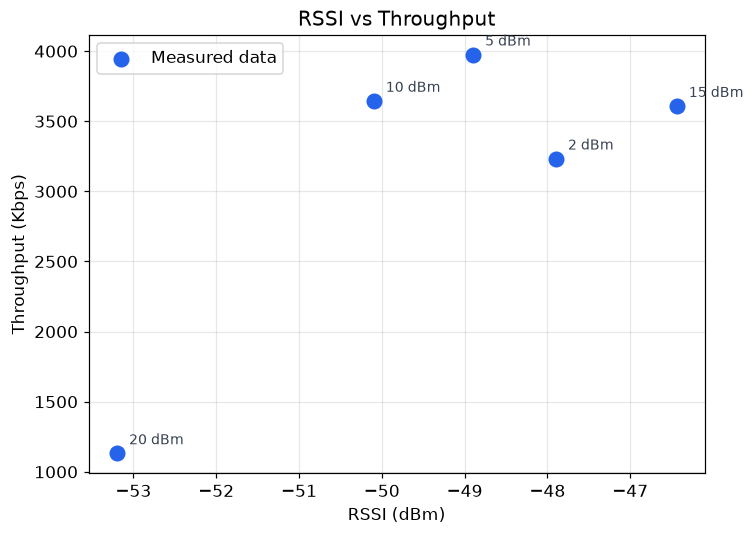

In [3]:
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(df["rssi_dbm"], df["throughput_kbps"], s=90, color="#2563eb", zorder=3, label="Measured data")

for _, row in df.iterrows():
    ax.annotate(f'{row.tx_power_dbm:g} dBm', (row.rssi_dbm, row.throughput_kbps),
                textcoords="offset points", xytext=(8, 6), fontsize=9, color="#374151")

ax.set_xlabel("RSSI (dBm)")
ax.set_ylabel("Throughput (Kbps)")
ax.set_title("RSSI vs Throughput")
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.savefig("scatter_plot.png")
plt.show()


## 3. Logarithmic Regression: y = a·ln(x) + b

RSSI ที่วัดได้เป็นค่าลบ (dBm) จึงใช้ x = -RSSI แทนความแรงของสัญญาณในเชิง "ระดับความอ่อนของสัญญาณ" (attenuation-like, ค่ายิ่งมากยิ่งอ่อน)
เพื่อให้ ln(x) นิยาม (x ต้องเป็นบวก) โดยสมการยังอ้างอิงกลับไปยังค่า RSSI จริงได้เสมอผ่านความสัมพันธ์ x = -RSSI

In [4]:
x = -df["rssi_dbm"].values  # x > 0 เสมอ (attenuation magnitude)
y = df["throughput_kbps"].values

def log_model(x, a, b):
    return a * np.log(x) + b

params, _ = optimize.curve_fit(log_model, x, y)
a, b = params

y_pred = log_model(x, a, b)
ss_res = np.sum((y - y_pred) ** 2)
ss_tot = np.sum((y - np.mean(y)) ** 2)
r2 = 1 - ss_res / ss_tot

print(f"สมการ Regression:  Throughput = {a:.3f} * ln(-RSSI) + {b:.3f}")
print(f"R-squared        :  {r2:.4f}")


สมการ Regression:  Throughput = -17335.830 * ln(-RSSI) + 70676.276
R-squared        :  0.6065


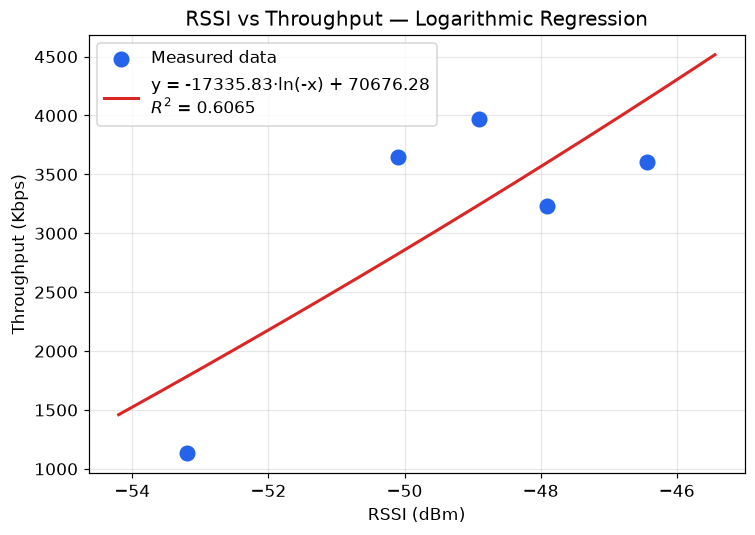

In [5]:
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(df["rssi_dbm"], df["throughput_kbps"], s=90, color="#2563eb", zorder=3, label="Measured data")

rssi_grid = np.linspace(df["rssi_dbm"].min() - 1, df["rssi_dbm"].max() + 1, 200)
throughput_fit = log_model(-rssi_grid, a, b)
ax.plot(rssi_grid, throughput_fit, color="#dc2626", linewidth=2,
        label=f"y = {a:.2f}·ln(-x) + {b:.2f}\n$R^2$ = {r2:.4f}")

ax.set_xlabel("RSSI (dBm)")
ax.set_ylabel("Throughput (Kbps)")
ax.set_title("RSSI vs Throughput — Logarithmic Regression")
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.savefig("regression_plot.png")
plt.show()


## 4. จุด Threshold RSSI ที่ Throughput ลดลงมากกว่า 50% จากค่าสูงสุด

หาค่า RSSI ที่ throughput ตกลงต่ำกว่าครึ่งหนึ่งของค่าสูงสุดที่วัดได้ในชุดข้อมูล โดยใช้การ interpolation เชิงเส้นระหว่างจุดข้อมูลที่คร่อมเส้น 50%

In [6]:
max_throughput = df["throughput_kbps"].max()
half_max = max_throughput / 2
print(f"Throughput สูงสุด : {max_throughput:.2f} Kbps")
print(f"เกณฑ์ 50%          : {half_max:.2f} Kbps")

df_sorted = df.sort_values("rssi_dbm").reset_index(drop=True)

threshold_rssi = None
for i in range(len(df_sorted) - 1):
    y0, y1 = df_sorted.loc[i, "throughput_kbps"], df_sorted.loc[i + 1, "throughput_kbps"]
    x0, x1 = df_sorted.loc[i, "rssi_dbm"], df_sorted.loc[i + 1, "rssi_dbm"]
    if (y0 - half_max) * (y1 - half_max) < 0:
        threshold_rssi = x0 + (half_max - y0) * (x1 - x0) / (y1 - y0)
        print(f"จุดตัด 50%: ระหว่าง RSSI {x0:.2f} dBm ({y0:.2f} Kbps) กับ {x1:.2f} dBm ({y1:.2f} Kbps)")

if threshold_rssi is not None:
    print(f"\n>>> Threshold RSSI ≈ {threshold_rssi:.2f} dBm")
    print("    (ที่ RSSI อ่อนกว่าค่านี้ Throughput จะเริ่มตกลงมากกว่า 50% จากระดับสูงสุด)")
else:
    print("\n>>> ไม่มีจุดข้อมูลใดที่ throughput ต่ำกว่า 50% ของค่าสูงสุดในช่วง RSSI ที่วัดได้")


Throughput สูงสุด : 3974.27 Kbps
เกณฑ์ 50%          : 1987.13 Kbps
จุดตัด 50%: ระหว่าง RSSI -53.20 dBm (1130.92 Kbps) กับ -50.10 dBm (3644.65 Kbps)

>>> Threshold RSSI ≈ -52.14 dBm
    (ที่ RSSI อ่อนกว่าค่านี้ Throughput จะเริ่มตกลงมากกว่า 50% จากระดับสูงสุด)


## 5. สรุปผล

- ข้อมูลจากการทดลองมีความแปรปรวนสูง (RSSI อยู่ในช่วงแคบ ≈ -46 ถึง -53 dBm เพราะระยะห่างจริงระหว่างบอร์ดคงที่ ปรับเฉพาะ Tx Power) ทำให้ค่า $R^2$ ของสมการ Logarithmic Regression อาจไม่สูงมากนัก
- จุดที่ RSSI อ่อนที่สุด (-53.2 dBm, Tx Power 20 dBm) กลับให้ Throughput ต่ำที่สุดในชุดข้อมูล ซึ่งเป็นจุดเดียวที่ตกต่ำกว่าเกณฑ์ 50% ของค่าสูงสุด
- ควรเก็บข้อมูลเพิ่มเติม (เพิ่มระยะห่างจริงระหว่าง Node A/B หรือเพิ่มจำนวนรอบทดลอง) เพื่อให้ได้ช่วง RSSI ที่กว้างขึ้นและสมการถดถอยที่แม่นยำขึ้น